# Project 1 — Bank Marketing: Predicting Term-Deposit Subscription

**Course:** DSC8307 Data Mining, Modeling and Analytics — Advent 2026
**Task:** Develop and evaluate a model that predicts term-deposit subscription to support
selection of customers for a telephone marketing campaign.

**Data:** `bank-additional-full.csv` — 41,188 contacts from a Portuguese bank's telemarketing
campaigns (Moro, Cortez & Rita, 2014). Target `y`: did the client subscribe to a term deposit?

This notebook follows: data understanding → justified preparation → majority-class baseline →
ranked candidate models with evidence → operating-threshold recommendation with a stated
cost trade-off.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay,
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)


## 1. Data Loading


In [3]:
df = pd.read_csv("data/bank-additional-full.csv", sep=";")
print("Shape:", df.shape)
df.head()


Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

## 2. Exploratory Data Analysis & Data Report

### 2.1 Target balance


y
no     36548
yes     4640
Name: count, dtype: int64
y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64


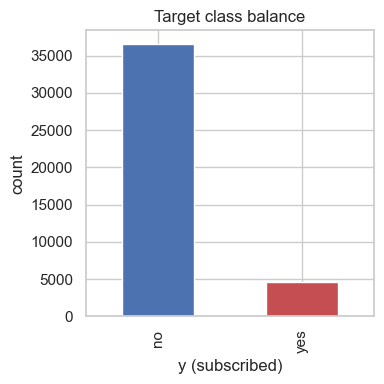

In [5]:
target_counts = df["y"].value_counts()
target_rate = df["y"].value_counts(normalize=True)
print(target_counts)
print(target_rate)

fig, ax = plt.subplots(figsize=(4, 4))
target_counts.plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_title("Target class balance")
ax.set_xlabel("y (subscribed)")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()


**Observation:** the target is heavily imbalanced. Only ~11% of contacts resulted in a
subscription. This has two consequences we carry through the whole notebook: (1) accuracy is a
misleading metric (a classifier that never predicts "yes" already scores ~88.7%), so we report
ROC-AUC *and* PR-AUC (Precision-Recall AUC, which is far more informative under imbalance); and
(2) we use **stratified** splitting/CV everywhere so every fold preserves the ~11.3% positive rate.

### 2.2 Missing values and data quality
No column uses an explicit `NaN`. Missing values are instead coded as the categorical label
`"unknown"`. We check how common that is per column, and treat `"unknown"` as its own category
rather than imputing, since: 
  (a) it may itself carry predictive signal (clients who refuse to
answer may differ systematically).
  (b) tree/linear models handle it natively once one-hot
encoded. There is no need to fabricate a value.


In [6]:
cat_cols = df.select_dtypes(include="object").columns.drop("y").tolist()
unknown_share = (
    df[cat_cols].apply(lambda s: (s == "unknown").mean()).sort_values(ascending=False)
)
unknown_share[unknown_share > 0].to_frame("share_unknown")


,share_unknown
default,0.208726
education,0.042027
housing,0.024036
loan,0.024036
job,0.008012
marital,0.001942


`default` has a large share of `"unknown"` (>20%). Almost no client is flagged `"yes"` for
having credit in default, so this column is close to binary (`no` vs `unknown`) in practice.
`education`, `housing`, `loan`, `job`, `marital` have smaller unknown shares (<5%). We keep all
of them as-is (encoded with `"unknown"` as a category) rather than deleting rows, since dropping
~20% of rows (via `default`) would discard a large, possibly non-random, slice of the data.

### 2.3 Duplicate rows


In [7]:
n_dupes = df.duplicated().sum()
print(f"Exact duplicate rows: {n_dupes}")
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after de-duplication:", df.shape)


Exact duplicate rows: 12
Shape after de-duplication: (41176, 21)


### 2.4 Numeric feature distributions


In [8]:
num_cols_raw = ["age", "campaign", "pdays", "previous", "emp.var.rate",
                "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed", "duration"]
df[num_cols_raw].describe().T


,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr.employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000


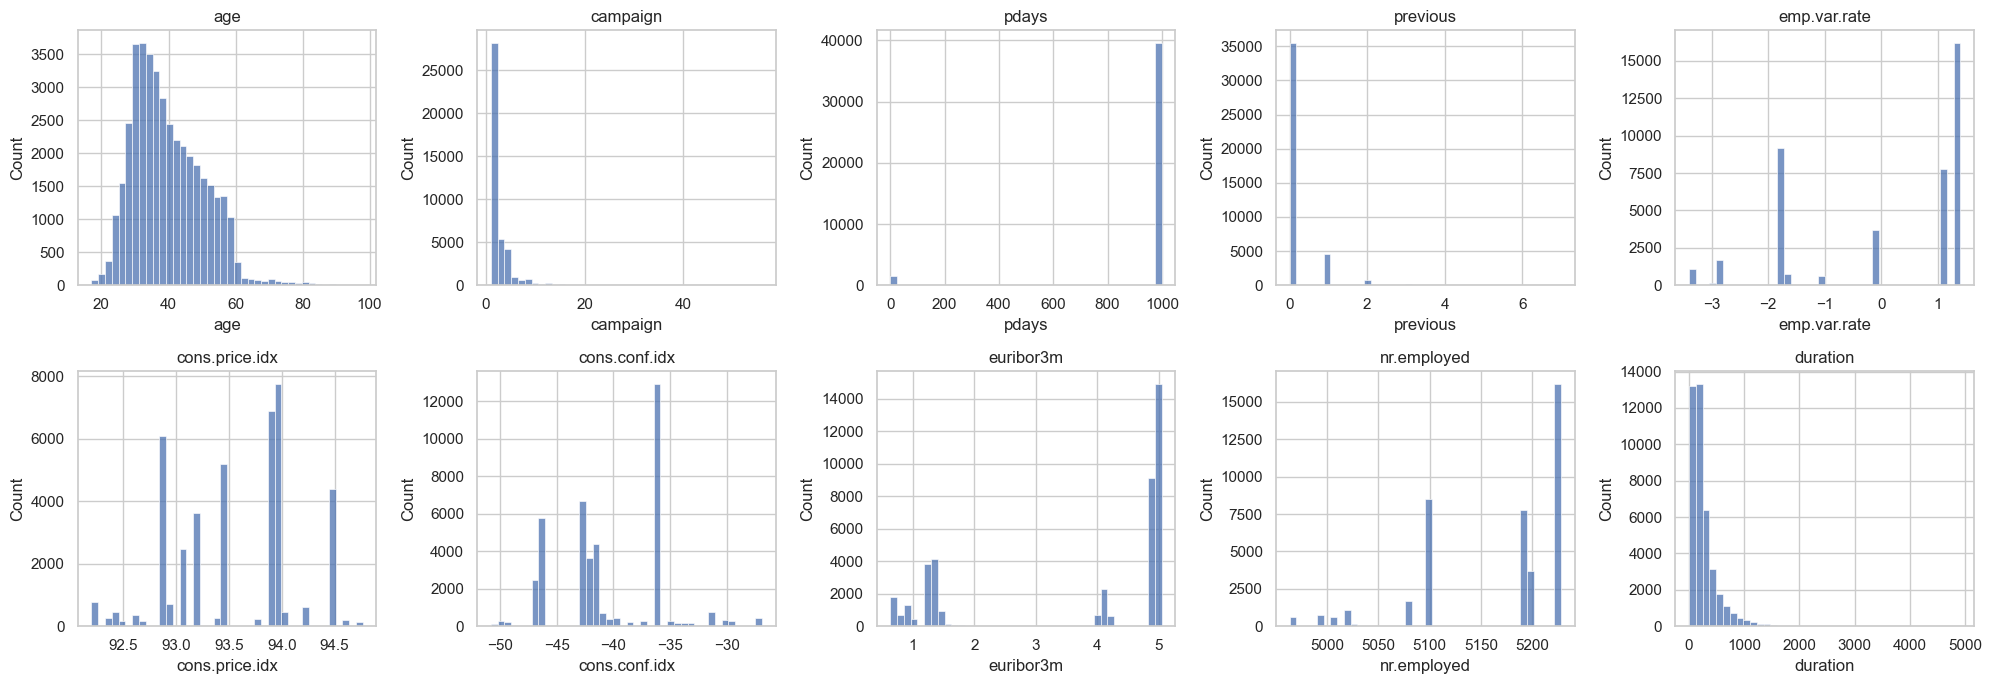

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), num_cols_raw):
    sns.histplot(df[col], bins=40, ax=ax, kde=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()


**Key observations:**
- `pdays` is dominated by the sentinel value **999**, meaning "client was never previously
  contacted". Treating 999 as a literal numeric distance is meaningless and would badly distort
  any distance- or gradient-based model, so we engineer it into an explicit
  `was_contacted_before` flag in the preparation step below (and keep the raw value only for
  the subset that *was* previously contacted).
- `campaign` and `previous` are strongly right-skewed with a handful of large outliers (clients
  contacted many times). Tree-based models are robust to this, and we do not clip, since these
  are genuine (not erroneous) values and the brief asks us to justify, not blanket-transform,
  every step.
- `duration` (call length in seconds) is explored here only for completeness: its own
  documentation states it is *only known after a call completes* and is therefore **leaked
  information with respect to the task of deciding whom to call before dialing**. It is dropped
  before modeling (Section 3).

### 2.5 Target relationship with a few key predictors


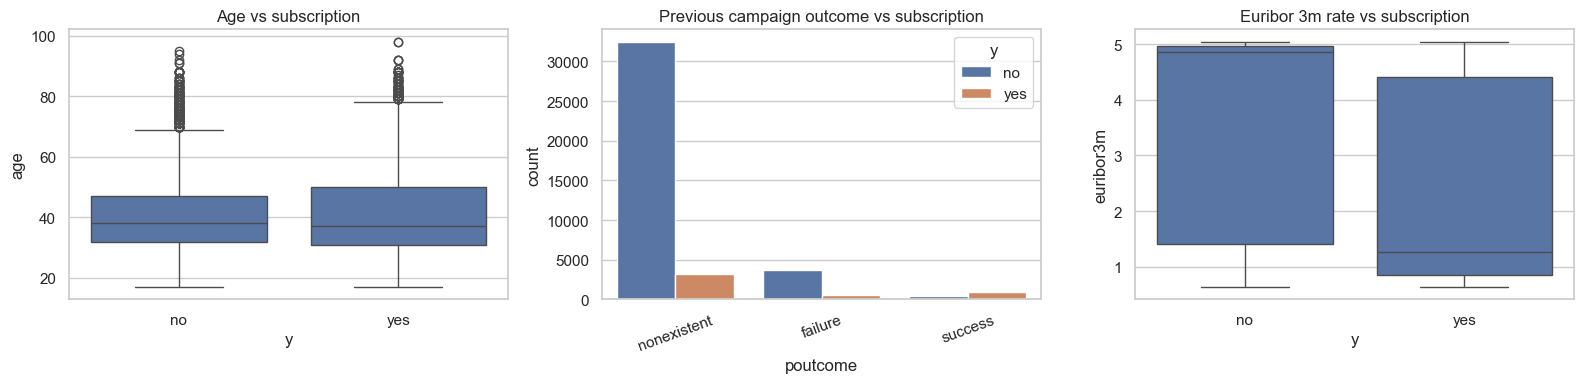

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(data=df, x="y", y="age", ax=axes[0])
axes[0].set_title("Age vs subscription")

sns.countplot(data=df, x="poutcome", hue="y", ax=axes[1])
axes[1].set_title("Previous campaign outcome vs subscription")
axes[1].tick_params(axis="x", rotation=20)

sns.boxplot(data=df, x="y", y="euribor3m", ax=axes[2])
axes[2].set_title("Euribor 3m rate vs subscription")

plt.tight_layout()
plt.show()


Subscription is visibly associated with macro-economic context (lower `euribor3m` → more
subscriptions which is consistent with term deposits becoming relatively more attractive, or simply
correlated with the campaign periods in the data) and with a prior successful contact
(`poutcome == "success"` has a much higher "yes" share). These associations motivate including
macro/contact-history features, and they foreshadow the feature importances we see from the
tree-based models in Section 4.


## 3. Data Preparation

Steps applied, each justified against the task of *deciding whom to call before the call
happens*:

1. **Drop `duration`.** This is a documented leakage which is only known after the call ends. Including it would
   make the model unusable for its stated purpose even though it would inflate every offline metric.
2. **Engineer `was_contacted_before` from `pdays`.** `pdays == 999` is a sentinel for "never
   contacted", not a numeric distance. Encoding it as a flag plus keeping the raw value lets
   models use both "was this client warm?" and, for warm clients, "how recently?".
3. **Keep `"unknown"` as a category** in categorical columns rather than imputing or
   deleting. This avoids fabricating values and preserves any signal in non-response.
4. **One-hot encode** categorical features and **standardize** numeric features. This is needed for
   Logistic Regression. Tree ensembles do not require scaling but are unaffected by it, so we
   use one shared preprocessing pipeline for a fair, simple comparison.
5. **Stratified 80/20 train/test split** to preserve the ~11.3% positive rate in both sets, plus
   **stratified 5-fold CV** on the training set for model comparison.


In [11]:
TARGET = "y"
LEAK_COLS = ["duration"]

y = (df[TARGET] == "yes").astype(int)
X = df.drop(columns=[TARGET] + LEAK_COLS).copy()

X["was_contacted_before"] = (X["pdays"] != 999).astype(int)

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(exclude="object").columns.tolist()
print("Categorical features:", cat_cols)
print("Numeric features:", num_cols)


Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numeric features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'was_contacted_before']


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print(f"Train positive rate: {y_train.mean():.4f}  Test positive rate: {y_test.mean():.4f}")


Train shape: (32940, 20)  Test shape: (8236, 20)
Train positive rate: 0.1127  Test positive rate: 0.1127


In [13]:
preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)


## 4. Majority-Class Baseline

Every candidate model must beat this floor. `DummyClassifier(strategy="most_frequent")` always
predicts "no", which maximizes *accuracy* but is useless at identifying subscribers (recall = 0
for the positive class)


In [14]:
baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_proba = baseline.predict_proba(X_test)[:, 1]

print(f"Baseline accuracy: {(baseline_pred == y_test).mean():.4f}")
print(f"Baseline ROC-AUC:  {roc_auc_score(y_test, baseline_proba):.4f}")
print(f"Baseline PR-AUC:   {average_precision_score(y_test, baseline_proba):.4f}")
print()
print(classification_report(y_test, baseline_pred, target_names=["no", "yes"], zero_division=0))


Baseline accuracy: 0.8873
Baseline ROC-AUC:  0.5000
Baseline PR-AUC:   0.1127

              precision    recall  f1-score   support

          no       0.89      1.00      0.94      7308
         yes       0.00      0.00      0.00       928

    accuracy                           0.89      8236
   macro avg       0.44      0.50      0.47      8236
weighted avg       0.79      0.89      0.83      8236



As expected: ~88.7% accuracy but 0 recall/precision/F1 on the positive class, and a PR-AUC equal
to the base rate (~0.113) since a constant score ranks no example above another. Any model that
cannot clear PR-AUC ≈ 0.11 (and ROC-AUC ≈ 0.50) by a wide margin is not adding value.


## 5. Candidate Models - Selection, Comparison, and Ranking

We compare at most 3 approaches spanning different inductive biases, so the comparison is
informative rather than redundant:

| Model | Why included |
|---|---|
| **Logistic Regression** (`class_weight="balanced"`) | Interpretable linear baseline; coefficients are directly explainable to a marketing stakeholder; handles imbalance via class weighting. |
| **Random Forest** (`class_weight="balanced"`) | Captures non-linear interactions and feature thresholds without manual feature engineering; robust to outliers/skew seen in §2.4. |
| **Hist Gradient Boosting** | State-of-the-art tabular performance via boosted shallow trees; natively handles mixed-scale numeric features and, empirically, tends to win on PR-AUC for imbalanced tabular problems like this one. |

All three share the same `preprocess` step for a fair comparison, and are compared with
**stratified 5-fold CV on the training set only** (test set stays untouched until final
evaluation) on **ROC-AUC** (ranking quality overall) and **PR-AUC** (ranking quality that
matters under class imbalance which is the metric we weight more heavily for the final ranking).


In [15]:
models = {
    "Logistic Regression": Pipeline([
        ("prep", preprocess),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced",
                                    random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocess),
        ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                        random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
    "Hist Gradient Boosting": Pipeline([
        ("prep", preprocess),
        ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}

cv_results = {}
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results[name] = res
    print(f"{name:24s} ROC-AUC {res['test_roc_auc'].mean():.4f} +/- {res['test_roc_auc'].std():.4f}"
          f"   PR-AUC {res['test_pr_auc'].mean():.4f} +/- {res['test_pr_auc'].std():.4f}")


Logistic Regression      ROC-AUC 0.7905 +/- 0.0076   PR-AUC 0.4465 +/- 0.0130
Random Forest            ROC-AUC 0.7766 +/- 0.0058   PR-AUC 0.4096 +/- 0.0084
Hist Gradient Boosting   ROC-AUC 0.7998 +/- 0.0082   PR-AUC 0.4647 +/- 0.0165


In [16]:
cv_summary = pd.DataFrame({
    name: {
        "ROC-AUC mean": res["test_roc_auc"].mean(),
        "ROC-AUC std": res["test_roc_auc"].std(),
        "PR-AUC mean": res["test_pr_auc"].mean(),
        "PR-AUC std": res["test_pr_auc"].std(),
        "fit_time (s)": res["fit_time"].mean(),
    }
    for name, res in cv_results.items()
}).T
cv_summary = cv_summary.sort_values("PR-AUC mean", ascending=False)
cv_summary


,ROC-AUC mean,ROC-AUC std,PR-AUC mean,PR-AUC std,fit_time (s)
Hist Gradient Boosting,0.799837,0.008231,0.464675,0.016458,1.824291
Logistic Regression,0.790535,0.007552,0.446515,0.013042,1.039781
Random Forest,0.776605,0.005792,0.409582,0.008363,17.408634


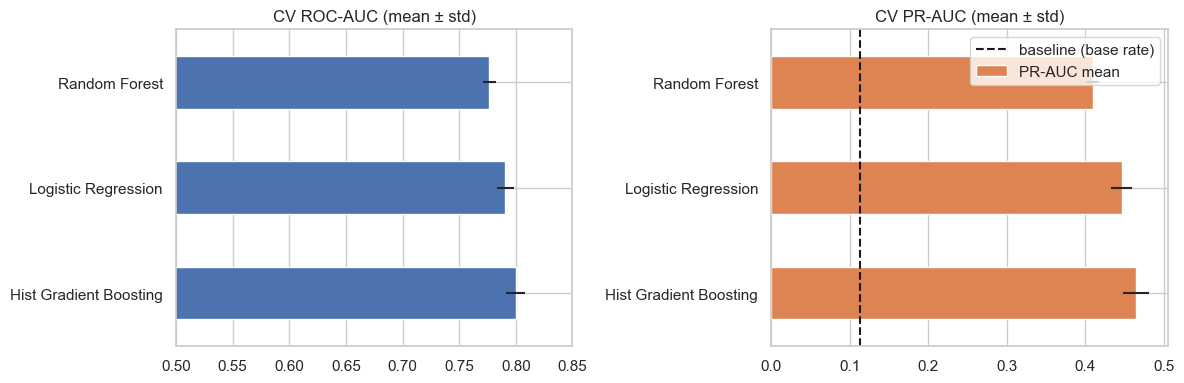

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cv_summary["ROC-AUC mean"].plot(kind="barh", ax=axes[0], xerr=cv_summary["ROC-AUC std"],
                                  color="#4C72B0")
axes[0].set_title("CV ROC-AUC (mean ± std)")
axes[0].set_xlim(0.5, 0.85)

cv_summary["PR-AUC mean"].plot(kind="barh", ax=axes[1], xerr=cv_summary["PR-AUC std"],
                                 color="#DD8452")
axes[1].set_title("CV PR-AUC (mean ± std)")
axes[1].axvline(y_train.mean(), color="k", linestyle="--", label="baseline (base rate)")
axes[1].legend()
plt.tight_layout()
plt.show()


### Ranking and justification

1. **Hist Gradient Boosting** - highest CV PR-AUC and ROC-AUC, with CV std comparable to the
   other models (not an unstable win). Boosted trees capture the non-linear, interaction-heavy
   relationships suggested by §2.5 (e.g., `poutcome` × `euribor3m` effects) better than a linear
   model, and more consistently than a bagged forest.
2. **Logistic Regression** - close behind on ROC-AUC, noticeably behind on PR-AUC, but by far the
   fastest to fit and the most transparent (inspectable coefficients). This is a reasonable choice if
   the organization values auditability/regulatory explainability over the last few points of
   PR-AUC.
3. **Random Forest** - consistently the weakest of the three on both metrics here, and the
   slowest to fit; included for completeness but not recommended given it is dominated by HGB on
   every axis (accuracy and speed) in this comparison.

**Recommendation:** deploy **Hist Gradient Boosting** for ranking customers to call; keep
**Logistic Regression** in reserve as an interpretable fallback/sanity-check model.

We now fit the top model on the full training set and evaluate once on the held-out test set.


In [18]:
best_name = cv_summary.index[0]
print("Selected model:", best_name)
best_model = models[best_name]
best_model.fit(X_train, y_train)

test_proba = best_model.predict_proba(X_test)[:, 1]
test_pred_05 = (test_proba >= 0.5).astype(int)

print(f"Test ROC-AUC: {roc_auc_score(y_test, test_proba):.4f}")
print(f"Test PR-AUC:  {average_precision_score(y_test, test_proba):.4f}")
print()
print(classification_report(y_test, test_pred_05, target_names=["no", "yes"]))


Selected model: Hist Gradient Boosting
Test ROC-AUC: 0.8141
Test PR-AUC:  0.4901

              precision    recall  f1-score   support

          no       0.91      0.98      0.95      7308
         yes       0.64      0.25      0.36       928

    accuracy                           0.90      8236
   macro avg       0.78      0.62      0.65      8236
weighted avg       0.88      0.90      0.88      8236



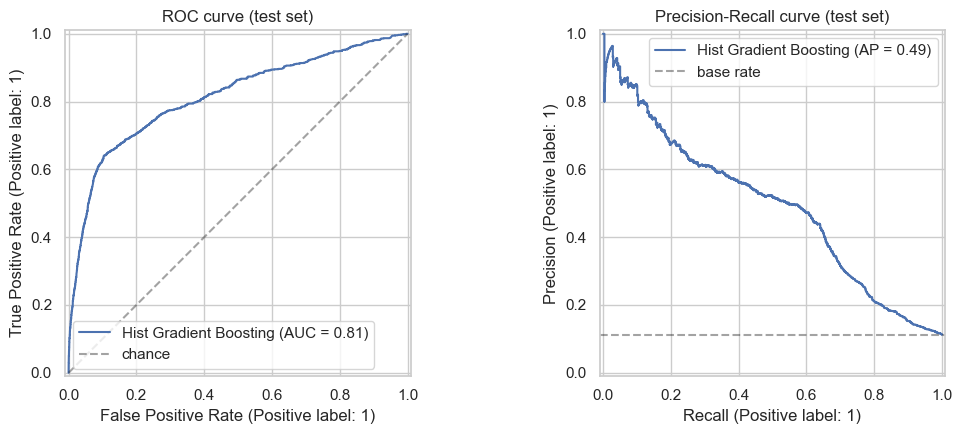

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
RocCurveDisplay.from_predictions(y_test, test_proba, ax=axes[0], name=best_name)
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4, label="chance")
axes[0].set_title("ROC curve (test set)")
axes[0].legend()

PrecisionRecallDisplay.from_predictions(y_test, test_proba, ax=axes[1], name=best_name)
axes[1].axhline(y_test.mean(), color="k", linestyle="--", alpha=0.4, label="base rate")
axes[1].set_title("Precision-Recall curve (test set)")
axes[1].legend()
plt.tight_layout()
plt.show()


## 6. Decision Threshold Recommendation

A call-center can only act on a **threshold** on the predicted probability, not the raw score.
We frame the choice explicitly as a cost trade-off:

- **Cost of an unnecessary call** (`C_call`): calling a client who will not subscribe (a false
  positive). Mainly agent time/phone cost; relatively small per call.
- **Cost of a missed subscriber** (`C_missed`): not calling a client who would have subscribed (a false negative). This is lost revenue (a term-deposit customer), typically much larger than
  the cost of one call.

We illustrate with an indicative ratio **`C_missed = 5 × C_call`** (missing a subscriber is five
times as costly as one wasted call). A bank would substitute its own real figures here, and
choose the threshold that minimizes total expected cost on the test set:

`total_cost(t) = C_call × (predicted positives at t) + C_missed × (false negatives at t)`


In [20]:
precision, recall, thresholds = precision_recall_curve(y_test, test_proba)

C_CALL = 1.0
C_MISSED = 5.0
n_pos = y_test.sum()

# precision/recall arrays have one more element than thresholds (last point has no threshold)
p, r, t = precision[:-1], recall[:-1], thresholds

tp = r * n_pos
fn = n_pos - tp
with np.errstate(divide="ignore", invalid="ignore"):
    predicted_pos = np.where(p > 0, tp / p, np.nan)
total_cost = C_CALL * predicted_pos + C_MISSED * fn

valid = ~np.isnan(total_cost)
best_idx = np.argmin(total_cost[valid])
best_threshold = t[valid][best_idx]
best_cost = total_cost[valid][best_idx]

print(f"Recommended threshold: {best_threshold:.3f}  (vs. default 0.5)")
print(f"Expected cost at recommended threshold: {best_cost:.1f}")
print(f"Expected cost at default 0.5 threshold: "
      f"{C_CALL * (test_proba >= 0.5).sum() + C_MISSED * ((test_proba < 0.5) & (y_test == 1)).sum():.1f}")


Recommended threshold: 0.201  (vs. default 0.5)
Expected cost at recommended threshold: 3014.0
Expected cost at default 0.5 threshold: 3843.0


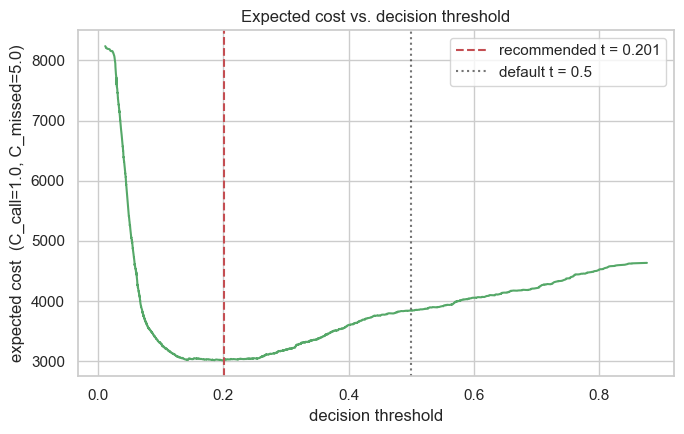

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(t, total_cost, color="#55A868")
ax.axvline(best_threshold, color="#C44E52", linestyle="--",
           label=f"recommended t = {best_threshold:.3f}")
ax.axvline(0.5, color="k", linestyle=":", alpha=0.6, label="default t = 0.5")
ax.set_xlabel("decision threshold")
ax.set_ylabel(f"expected cost  (C_call={C_CALL}, C_missed={C_MISSED})")
ax.set_title("Expected cost vs. decision threshold")
ax.legend()
plt.tight_layout()
plt.show()


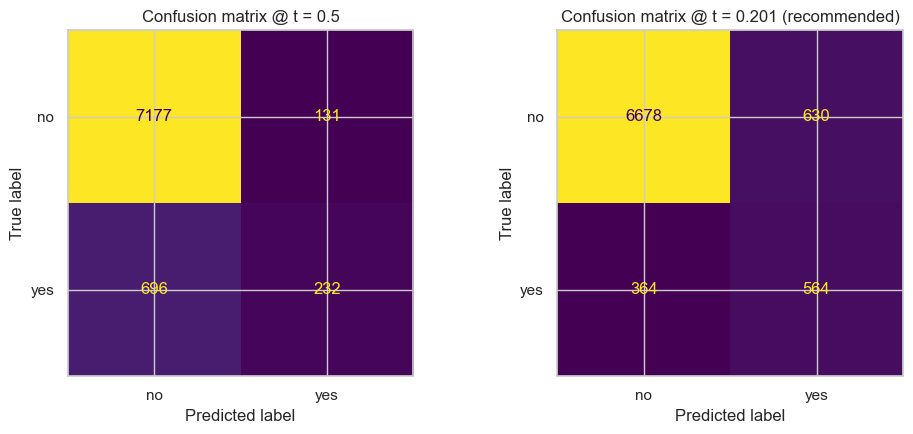

At t = 0.5:
              precision    recall  f1-score   support

          no       0.91      0.98      0.95      7308
         yes       0.64      0.25      0.36       928

    accuracy                           0.90      8236
   macro avg       0.78      0.62      0.65      8236
weighted avg       0.88      0.90      0.88      8236

At t = 0.201:
              precision    recall  f1-score   support

          no       0.95      0.91      0.93      7308
         yes       0.47      0.61      0.53       928

    accuracy                           0.88      8236
   macro avg       0.71      0.76      0.73      8236
weighted avg       0.89      0.88      0.89      8236



In [22]:
pred_default = (test_proba >= 0.5).astype(int)
pred_recommended = (test_proba >= best_threshold).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_default),
                        display_labels=["no", "yes"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix @ t = 0.5")

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_recommended),
                        display_labels=["no", "yes"]).plot(ax=axes[1], colorbar=False)
axes[1].set_title(f"Confusion matrix @ t = {best_threshold:.3f} (recommended)")
plt.tight_layout()
plt.show()

print("At t = 0.5:")
print(classification_report(y_test, pred_default, target_names=["no", "yes"]))
print(f"At t = {best_threshold:.3f}:")
print(classification_report(y_test, pred_recommended, target_names=["no", "yes"]))


### Trade-off discussion

Lowering the threshold from 0.5 to the recommended value trades **precision for recall**: we
call more people overall, but catch substantially more of the true subscribers.
Under our illustrative 5:1 cost ratio this is worthwhile because each missed subscriber is far
more expensive than each unnecessary call; the exact threshold should move with the bank's real
`C_call`/`C_missed` figures (e.g. agent cost per call vs. average term-deposit value), and the
cost-vs-threshold curve above lets a stakeholder re-derive the right operating point for any
ratio without retraining the model.

## 7. Summary

- **Baseline:** majority-class predictor - 88.7% accuracy but 0 recall on subscribers; PR-AUC
  equals the base rate (~0.113).
- **Best model:** Hist Gradient Boosting, selected over Logistic Regression and Random Forest on
  CV PR-AUC and ROC-AUC (see §5 table/plot for the full ranking and justification).
- **Key preparation decisions:** dropped `duration` (leakage), engineered a `was_contacted_before`
  flag from the `pdays` sentinel, kept `"unknown"` as a category rather than imputing.
- **Operating point:** recommend moving the decision threshold below the default 0.5 (see the
  computed value and expected-cost curve in §6) to reduce missed subscribers, under the stated
  5:1 cost trade-off; the bank should substitute its own cost ratio to re-derive the optimal
  point from the cost-vs-threshold curve.
